# Output fidelity of the last_3 2011 predictor (roadmap Work 6, pilot)

The predictor's own death probabilities are the **teacher**. This notebook asks how closely a small linear readout of the selected concept scores reproduces the teacher. The readout is fitted on reference-year rows only, then frozen, then scored on held-out patients. Deaths never enter the fit or the scores.

The steps are settings, loads, then pre-run checks. The checks write `checks.csv` and stop the notebook when any check fails, before any readout column is built. Readout fitting and scoring come after the checks pass.

Runs on Fiji in `~/SAE-TCAV`. Output folder: `$RPI_OUT_DIR`.

## Which build, years, roles, sizes and folders does the pilot use?

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

from concept_study import paths

BUILD = ("last_3", 2011)                 # pilot build, fixed before any scoring
REFERENCE = BUILD[1]
YEARS = (2011, 2012, 2013, 2014, 2015)   # reference year, then later years with teacher outputs
FIT_ROLES = ("rule_discovery", "cav_fit", "concept_selection")   # the only reference-year roles that may fit a readout
EXPECTED_FIT_ROWS = 630
EXPECTED_EVALUATION_ROWS = {2011: 314, 2012: 326, 2013: 334, 2014: 333, 2015: 294}
SAE_SEEDS = paths.SAE_SEEDS              # the three frozen SAE dictionaries
DEVICE = "cuda"                          # frozen SAE encoder and head
BATCH_ROWS = 512                         # rows per head replay batch
FOLDS = 5                                # patient-grouped folds for the ridge strength
ALPHAS = np.logspace(-3, 4, 22)          # ridge strengths, 1e-3 to 1e4, log-spaced
RANDOM_SEEDS = range(1, 101)             # seeds of the random-direction comparator
STRATUM_LEVELS = np.round(np.arange(0.05, 1.0, 0.05), 2)   # teacher quantiles 5% to 95% of the reference fit rows
BOOTSTRAP_REPLICATES = paths.BOOTSTRAP_REPLICATES
BOOTSTRAP_SEED = paths.BOOTSTRAP_SEED
WORK1_FILE = (paths.OUTPUT / "extensions" / "temporal_input_attribution" / "generated_state"
              / "work1_v5_primary" / "private" / f"{BUILD[0]}_{BUILD[1]}.npz")
OUTPUT = Path(os.environ["RPI_OUT_DIR"])  # run output folder, set by the launcher
FIGURES = OUTPUT / "figures"
NAMED_COMPARATORS = ("concept_factors", "group_scores", "rule_indicators", "pca", "raw_embedding")
MEASURES = ("probability_mse", "probability_mae", "log_odds_mse")
ARM_LABELS = {"historical": "primary (historical scaling)", "scaling sensitivity": "scaling sensitivity"}

## Which reference-year rows may fit the readouts?

The develop-mode load returns only reference-year `rule_discovery`, `cav_fit` and `concept_selection` rows, with labels hidden (NaN), so the fit cannot see deaths.

In [2]:
from concept_study import loading, measures

inputs = loading.open_inputs(DEVICE)
frozen_roles = next(item["roles"] for item in inputs["inventory"] if (item["build"], item["reference"]) == BUILD)
record = next(r for r in measures.load_index()["builds"] if (r["build"], r["reference"]) == BUILD)
develop_inputs = {**inputs, "ctx": {**inputs["ctx"], "mode": "develop"}}
fit = loading.load_build(develop_inputs, *BUILD, frozen_roles)
print("fit rows:", len(fit["row_index"]))
print(pd.Series(fit["roles"]).value_counts().to_string())
print("years:", sorted(set(fit["years"].tolist())), "| labelled rows:", int(np.isfinite(fit["labels"]).sum()))

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fit rows: 630
rule_discovery       315
cav_fit              158
concept_selection    157
years: [2011] | labelled rows: 0


## Which evaluation rows are held out, and which rows must the evaluate-mode load drop?

The evaluate-mode load also returns reference-year and later `rule_discovery` rows, and those belong to fit patients. Only the `evaluation` role is kept for scoring.

In [3]:
evaluated = loading.load_build(inputs, *BUILD, frozen_roles)
evaluation = np.flatnonzero(evaluated["roles"] == "evaluation")
print("rows returned:", len(evaluated["row_index"]), "| evaluation rows kept:", len(evaluation))
print(pd.Series(evaluated["roles"]).value_counts().to_string())
print(pd.Series(evaluated["years"][evaluation]).value_counts().sort_index().to_string())

rows returned: 2745 | evaluation rows kept: 1601
evaluation        1601
rule_discovery    1144
2011    314
2012    326
2013    334
2014    333
2015    294


## Do the frozen reference objects agree with the patient table?

`reference_data` raises if the frozen scaler or SAE-training rows differ from the frozen ones, or if the evaluation rows differ from the patient table. `sae_encoders` are the frozen SAE encoders that build the readout columns.

In [4]:
from concept_study import alternative_bases

import time

timings = {}
started = time.perf_counter()
data = alternative_bases.reference_data(inputs, record)
timings["reference_data_seconds"] = time.perf_counter() - started
table = data["table"]
encoders = alternative_bases.sae_encoders(data)
print("patient table rows:", len(table["patient_id"]), "| years:", sorted(set(table["year"].tolist())))

patient table rows: 1601 | years: [2011, 2012, 2013, 2014, 2015]


## Is the Work 1 consistent-scaling file keyed to the same evaluation rows?

Work 1 holds the consistent-scaling values of the evaluation rows. Its historical arm is the cache, so it is also checked against the patient table below. The consistent arm is used only in the scaling-sensitivity step.

In [5]:
with np.load(WORK1_FILE) as stored:
    work1 = {name: stored[name] for name in stored.files}
print(len(work1["year"]), "rows in", WORK1_FILE.name)

1601 rows in last_3_2011.npz


## Do the row counts and fit-row roles match the research counts?

Each check appends one row to `checks`. Nothing is written until the last check cell.

In [6]:
import concept_candidates as cc
import concept_subgroup_drift_pilot as pilot

checks = []


def record_check(name, measured, expected, source, passed):
    checks.append({"name": name, "measured": measured, "expected": expected, "source": source, "passed": bool(passed)})


record_check("fit rows", len(fit["row_index"]), EXPECTED_FIT_ROWS, "research Q1 role table",
             len(fit["row_index"]) == EXPECTED_FIT_ROWS)
for year in YEARS:
    count = int((evaluated["years"][evaluation] == year).sum())
    record_check(f"evaluation rows {year}", count, EXPECTED_EVALUATION_ROWS[year], "research Q1 later-year table",
                 count == EXPECTED_EVALUATION_ROWS[year])

population = inputs["population"]
cache = inputs["caches"][BUILD[0]]
split = pilot.reference_year_roles(population, REFERENCE, seed=cache.config["split_seed"])
roles_identical = split["identity"] == frozen_roles["identity"]
record_check("recomputed reference roles match the frozen identity", roles_identical, True,
             "concept_candidates.py:453-458", roles_identical)
fit_roles_identical = bool(np.array_equal(fit["roles"], split["row_role"][fit["row_index"]]))
record_check("fit row roles equal the recomputed roles", fit_roles_identical, True,
             "cmr_common.py:568-570", fit_roles_identical)
try:
    cc.check_fit_rows(fit["row_index"], split["row_role"], population["year"], split["is_entrant"], REFERENCE, FIT_ROLES)
    fit_rows_message = "passed"
except ValueError as error:
    fit_rows_message = str(error)
record_check("fit rows pass check_fit_rows", fit_rows_message, "passed", "concept_candidates.py:22",
             fit_rows_message == "passed")

## Are the fit and evaluation patients separate, unique and unlabelled?

A fit patient must never be scored, and each patient has one reference-year row in the fit. Develop-mode rows carry no labels (`cmr_common.py:591`).

In [7]:
fit_patients = fit["patients"]
shared_patients = np.intersect1d(fit_patients, evaluated["patients"][evaluation])
unique_fit_patients = len(np.unique(fit_patients))
labelled_fit_rows = int(np.isfinite(fit["labels"]).sum())
record_check("fit patients appear once", unique_fit_patients, len(fit_patients), "research Q1 (one row per patient)",
             unique_fit_patients == len(fit_patients))
record_check("fit and evaluation patients shared, all evaluation years", len(shared_patients), 0,
             "research Q1; plan decision 4", len(shared_patients) == 0)
record_check("labelled fit rows (develop mode)", labelled_fit_rows, 0, "cmr_common.py:591", labelled_fit_rows == 0)

evaluation_patients = evaluated["patients"][evaluation].astype(str)
same_patient = bool(np.array_equal(evaluation_patients, table["patient_id"]))
same_year = bool(np.array_equal(evaluated["years"][evaluation], table["year"]))
same_probability = bool(np.array_equal(evaluated["probabilities"][evaluation, 1].astype(np.float32), table["probability"]))
record_check("evaluation patient ids equal the patient table", same_patient, True, "tcav_geometry.ipynb cell 7", same_patient)
record_check("evaluation years equal the patient table", same_year, True, "tcav_geometry.ipynb cell 7", same_year)
record_check("evaluation probabilities equal the patient table", same_probability, True, "tcav_geometry.ipynb cell 7",
             same_probability)

## Does the frozen head reproduce the stored probabilities and gradients on every row?

The loader replays the head on only 8 rows. Here it runs on all fit rows and all evaluation rows, with the pilot tolerances in `tcav_geometry.py`: probability `rtol 1e-4, atol 1e-5`, gradient `rtol 1e-3, atol 1e-5`.

In [8]:
import tcav_geometry as geometry

replay = {}
for label, base, rows in (("fit rows", fit, np.arange(len(fit["row_index"]))), ("evaluation rows", evaluated, evaluation)):
    probabilities = pilot.batched_death_probabilities(base["continuation"], base["embeddings"][rows], BATCH_ROWS)
    gradients = pilot.batched_death_gradients(base["continuation"], base["embeddings"][rows], BATCH_ROWS)
    replay[label] = geometry.replay_summary(probabilities, base["probabilities"][rows], gradients, base["gradients"][rows])
    record_check(f"head replay probability, {label}", replay[label]["probability_max_abs_error"],
                 "within rtol 1e-4 atol 1e-5", "tcav_geometry.py:63", replay[label]["probability_within_tolerance"])
    record_check(f"head replay gradient, {label}", replay[label]["gradient_max_abs_error"],
                 "within rtol 1e-3 atol 1e-5", "tcav_geometry.py:64", replay[label]["gradient_within_tolerance"])
print(pd.DataFrame(replay).T.to_string(float_format=lambda value: f"{value:.2e}"))

                 rows probability_max_abs_error probability_max_relative_error probability_within_tolerance gradient_max_abs_error gradient_max_relative_error gradient_within_tolerance
fit rows          630                  4.17e-07                       2.21e-06                         True               4.28e-08                    5.08e-02                      True
evaluation rows  1601                  4.77e-07                       2.84e-06                         True               4.66e-08                    6.41e-02                      True


## Do the frozen SAE encoders give the loader's codes, in float32?

The readout columns come from the frozen encoders applied to the same embeddings, so the encoded codes must equal the loader's codes. They are float32 here. The patient table stores float16 codes, which are not used (research Risk 8). The tolerance is the head-replay probability tolerance, since no separate code tolerance is given.

In [9]:
for label, base, rows in (("fit rows", fit, np.arange(len(fit["row_index"]))), ("evaluation rows", evaluated, evaluation)):
    largest_gap, within, dtypes = 0.0, True, set()
    for seed in SAE_SEEDS:
        encoded = encoders[seed](base["embeddings"][rows])
        loaded = base["codes"][seed][rows]
        dtypes.add(str(loaded.dtype))
        largest_gap = max(largest_gap, float(np.max(np.abs(encoded - loaded))))
        within = within and bool(np.allclose(encoded, loaded, **geometry.PROBABILITY_TOLERANCE))
    record_check(f"encoder codes equal loader codes, {label}", largest_gap,
                 "within rtol 1e-4 atol 1e-5 (largest over seeds)", "tcav_geometry.py:63", within)
    record_check(f"loader codes dtype, {label}", ",".join(sorted(dtypes)), "float32",
                 "concept_subgroup_drift_pilot.py:3020", dtypes == {"float32"})

## Do the Work 1 rows follow the patient table, and does its historical arm equal the cache?

Work 1 must be row-aligned with the patient table. Its historical probability must match the cached probability within the probability tolerance (research Q2 measured at most 1.06e-06).

In [10]:
work1_same_patient = bool(np.array_equal(work1["patient_id"].astype(str), table["patient_id"]))
work1_same_year = bool(np.array_equal(work1["year"], table["year"]))
record_check("Work 1 patient ids equal the patient table", work1_same_patient, True, "research Q2", work1_same_patient)
record_check("Work 1 years equal the patient table", work1_same_year, True, "research Q2", work1_same_year)

historical = work1["historical_actual_probability"]
same_shape = historical.shape == table["probability"].shape
work1_gap = float(np.max(np.abs(historical - table["probability"]))) if same_shape else np.inf
work1_within = same_shape and bool(np.allclose(historical, table["probability"], **geometry.PROBABILITY_TOLERANCE))
record_check("Work 1 historical probability vs cached probability (max abs)", work1_gap,
             "within rtol 1e-4 atol 1e-5", "research Q2", work1_within)

## Do all pre-run checks pass? If not, stop here.

`checks.csv` is written first, so a failure is recorded. The notebook then raises if any check failed, and no readout column is built.

In [11]:
OUTPUT.mkdir(parents=True, exist_ok=True)
checks_table = pd.DataFrame(checks)
checks_table.to_csv(OUTPUT / "checks.csv", index=False)
failed = checks_table.loc[~checks_table["passed"], "name"].tolist()
print(checks_table.to_string())
if failed:
    raise RuntimeError(f"{len(failed)} pre-run check(s) failed; no readout column is built: {failed}")
print(f"all {len(checks_table)} pre-run checks passed; written to {OUTPUT / 'checks.csv'}")

                                                             name  measured                                         expected                                source  passed
0                                                        fit rows       630                                              630                research Q1 role table    True
1                                            evaluation rows 2011       314                                              314          research Q1 later-year table    True
2                                            evaluation rows 2012       326                                              326          research Q1 later-year table    True
3                                            evaluation rows 2013       334                                              334          research Q1 later-year table    True
4                                            evaluation rows 2014       333                                              333          research Q1

## Which comparator columns does each row set get?

Six comparators are built from the frozen objects: concept factor scores (the medoid factor of each retained family, from the frozen SAE encoders), group scores (SD-scaled member means on the SAE-training rows, families with no usable member dropped), rule indicators (the frozen rules), PCA (ReLU of the leading components of the SAE-training rows, matched to the concept count), random 14-direction sets (100 seeds) and the raw 192-dimensional embedding. The constant benchmark has no columns. The matched size is the number of retained concepts found in the inventory.

In [12]:
from concept_study import bootstrap, measures

concept_items = [item for item in inputs["inventory"]
                 if (item["build"], item["reference"]) == BUILD and paths.PRIMARY_VARIANT in item["variants"]]
MATCHED_SIZE = len(concept_items)
medoids = [tuple(int(value) for value in item["frozen"]["medoid"]) for item in concept_items]
rules = [item["frozen"]["rule"] for item in concept_items]
members = {item["family"]: [(int(s), int(k)) for s, k in item["family_record"]["members"]] for item in concept_items}
fit_raw = data["scaler"].inverse_transform(data["fit_z"]).astype(np.float32)
fit_sae_codes = {seed: encoders[seed](fit_raw) for seed in SAE_SEEDS}
group_encode, group_info, group_dropped = cc.group_encoder(encoders, fit_sae_codes, members)
pca_encode = alternative_bases.on_raw(alternative_bases.pca_encoder(data["fit_z"], MATCHED_SIZE), data)
random_encoders = {seed: alternative_bases.on_raw(alternative_bases.random_encoder(192, MATCHED_SIZE, seed), data)
                   for seed in RANDOM_SEEDS}
print("retained concepts (matched size):", MATCHED_SIZE)
print("group scores kept:", len(group_info), "| dropped, every member has zero spread:", group_dropped)
print("members left out for zero spread:", sum(info["left_out"] for info in group_info))

retained concepts (matched size): 14
group scores kept: 14 | dropped, every member has zero spread: []
members left out for zero spread: 0


## What feature matrix does each comparator give a row set?

The same function builds the matrices for the fit rows, the historical evaluation rows and the consistent-scaling evaluation rows, so every comparator passes through the same frozen encoders.

In [13]:
def comparator_matrices(raw, X):
    """Feature matrix of every comparator for rows with raw embeddings `raw` and population features `X`."""
    codes = {seed: encoders[seed](raw) for seed in SAE_SEEDS}
    matrices = {
        "concept_factors": np.column_stack([codes[seed][:, factor] for seed, factor in medoids]),
        "group_scores": group_encode(raw),
        "rule_indicators": np.column_stack([rule.mask(X) for rule in rules]),
        "pca": pca_encode(raw),
        "raw_embedding": raw,
    }
    for seed in RANDOM_SEEDS:
        matrices[f"random_set_{seed}"] = random_encoders[seed](raw)
    return {name: np.asarray(matrix, dtype=np.float64) for name, matrix in matrices.items()}


fit_columns = comparator_matrices(fit["embeddings"], fit["X"])
for name in ("concept_factors", "group_scores", "rule_indicators", "pca", "raw_embedding", "random_set_1"):
    print(name, fit_columns[name].shape)

concept_factors (630, 14)
group_scores (630, 14)
rule_indicators (630, 14)
pca (630, 14)
raw_embedding (630, 192)
random_set_1 (630, 14)


## Are the readouts fitted on the fit rows only, and frozen before any evaluation row is scored?

Each comparator gets one ridge readout of the teacher log-odds, fitted on the 630 fit rows. The ridge strength is chosen by patient-grouped cross-validation on those rows. The file and its sha256 are written here, before the evaluation columns are built or any evaluation row is scored. Alphas on the edge of the grid are listed.

In [14]:
import datetime
import hashlib
import json

import output_fidelity as fidelity

run_started = datetime.datetime.now().isoformat(timespec="seconds")
started = time.perf_counter()
fit_teacher = fit["probabilities"].astype(np.float64)
readouts = {name: fidelity.fit_readout(matrix, fit_teacher, fit["patients"], ALPHAS, FOLDS)
            for name, matrix in fit_columns.items()}
constant_probability = float(fit_teacher[:, 1].mean())
constant_log_odds = float(fidelity.teacher_log_odds(fit_teacher).mean())
STRATUM_CUTS = np.quantile(fit_teacher[:, 1], STRATUM_LEVELS)
arrays = {f"{name}|{key}": np.asarray(value) for name, readout in readouts.items() for key, value in readout.items()}
arrays["constant_probability"] = np.asarray(constant_probability)
arrays["constant_log_odds"] = np.asarray(constant_log_odds)
arrays["stratum_cuts"] = STRATUM_CUTS
readouts_file = OUTPUT / "readouts.npz"
measures.save_atomic(readouts_file, **arrays)
readouts_sha256 = hashlib.sha256(readouts_file.read_bytes()).hexdigest()
grid_edge = [name for name, readout in readouts.items() if readout["alpha_on_grid_edge"]]
timings["fit_seconds"] = time.perf_counter() - started
run_record = {"started": run_started, "readouts_file": readouts_file.name, "readouts_sha256": readouts_sha256,
              "alpha_grid": [float(a) for a in ALPHAS], "alphas_on_grid_edge": grid_edge,
              "constant_probability": constant_probability, "constant_log_odds": constant_log_odds,
              "timings_seconds": dict(timings)}
(OUTPUT / "run_record.json").write_text(json.dumps(run_record, indent=2))
print(len(readouts), "readouts frozen; sha256", readouts_sha256)
print("alpha on grid edge:", grid_edge if grid_edge else "none")
print("constant probability (mean teacher on fit rows):", round(constant_probability, 5))
print("constant log-odds (mean teacher log-odds on fit rows):", round(constant_log_odds, 5))
print("stratum cuts (5% to 95% of fit teacher probability):", np.round(STRATUM_CUTS, 4))

105 readouts frozen; sha256 1130f904b6058deebc65b246dfbdee1f72463b85e98cbd220bedba45be95c99b
alpha on grid edge: ['rule_indicators', 'pca', 'random_set_1', 'random_set_2', 'random_set_3', 'random_set_5', 'random_set_6', 'random_set_9', 'random_set_10', 'random_set_11', 'random_set_12', 'random_set_16', 'random_set_21', 'random_set_22', 'random_set_26', 'random_set_27', 'random_set_28', 'random_set_29', 'random_set_30', 'random_set_31', 'random_set_36', 'random_set_39', 'random_set_43', 'random_set_46', 'random_set_47', 'random_set_49', 'random_set_52', 'random_set_53', 'random_set_56', 'random_set_58', 'random_set_66', 'random_set_67', 'random_set_69', 'random_set_71', 'random_set_76', 'random_set_78', 'random_set_80', 'random_set_81', 'random_set_82', 'random_set_85', 'random_set_88', 'random_set_91', 'random_set_92', 'random_set_93', 'random_set_94', 'random_set_95', 'random_set_96', 'random_set_98']
constant probability (mean teacher on fit rows): 0.08132
constant log-odds (mean tea

## Which evaluation columns does each arm get, after the readouts are frozen?

The historical arm uses the cached embeddings of the evaluation rows. The scaling-sensitivity arm passes the Work 1 consistent-scaling embeddings through the same frozen encoders. Rule indicators use the same features under both arms.

In [15]:
evaluation_X = evaluated["X"][evaluation]
historical_columns = comparator_matrices(evaluated["embeddings"][evaluation], evaluation_X)
consistent_columns = comparator_matrices(work1["consistent_actual_embedding"], evaluation_X)
print("historical rows:", historical_columns["concept_factors"].shape[0], "| consistent rows:", consistent_columns["concept_factors"].shape[0])

historical rows: 1601 | consistent rows: 1601


## Which teacher, years and patient draws does each evaluation row use?

The historical teacher is the cached probability. The consistent teacher is the Work 1 consistent-scaling probability, written as two columns. The patient bootstrap uses the population patient ids, 1000 draws with seed 20261106, and row 0 is the point estimate. The same draws are used for every comparator, year and arm.

In [16]:
historical_teacher = evaluated["probabilities"][evaluation].astype(np.float64)
consistent_p1 = work1["consistent_actual_probability"].astype(np.float64)
consistent_teacher = np.column_stack([1 - consistent_p1, consistent_p1])
row_years = evaluated["years"][evaluation]
index = measures.load_index()
draw_patients, patient_draws = bootstrap.patient_weights(measures.all_patient_ids(index))
row_draws = bootstrap.row_weights(table["patient_id"], draw_patients, patient_draws).astype(np.float64)
print("draws (replicates, rows):", row_draws.shape, "| row 0 is all ones:", bool(np.all(row_draws[0] == 1)))

draws (replicates, rows): (1001, 1601) | row 0 is all ones: True


## What does each frozen readout predict on the evaluation rows?

Each readout gives a probability from its own columns. The constant benchmark predicts the mean teacher probability on the fit rows.

In [17]:
def predictions(columns):
    named = {name: fidelity.predict_probability(readouts[name], columns[name]) for name in fit_columns}
    named["constant"] = np.full(len(row_years), constant_probability)
    return named


historical_predictions = predictions(historical_columns)
consistent_predictions = predictions(consistent_columns)

## How well does each frozen readout match the teacher in each year, with patient-bootstrap intervals?

The primary measure is the probability mean squared error on the held-out reference rows (2011, historical arm). The other measures are shown beside it. Intervals cover evaluation sampling only, because the readouts are frozen and not refitted in each draw. Spearman rank correlation is drawn per replicate for the five named comparators and is a point estimate for the random sets.

In [18]:
score_started = time.perf_counter()


def point_and_interval(draws):
    """Point estimate (replicate 0) and the 2.5% and 97.5% percentiles of the other replicates."""
    if len(draws) == 1:
        return float(draws[0]), np.nan, np.nan
    low, high = bootstrap.percentile_interval(draws[1:])
    return float(draws[0]), float(low), float(high)


def score_arm(predicted, teacher):
    """Draws of every measure for every comparator and year of one arm."""
    draws = {}
    for year in YEARS:
        mask = row_years == year
        weights = row_draws[:, mask]
        constant_errors = fidelity.bootstrap_errors(predicted["constant"][mask], teacher[mask], weights)
        constant_squared = (constant_log_odds - fidelity.teacher_log_odds(teacher[mask])) ** 2
        constant_errors["log_odds_mse"] = (weights @ constant_squared) / weights.sum(axis=1)
        for name in ("constant", *fit_columns):
            if name == "constant":
                errors = constant_errors
                errors["spearman"] = np.full(len(weights), np.nan)
            else:
                errors = fidelity.bootstrap_errors(predicted[name][mask], teacher[mask], weights)
                if name in NAMED_COMPARATORS:
                    errors["spearman"] = fidelity.bootstrap_spearman(predicted[name][mask], teacher[mask], weights)
                else:
                    errors["spearman"] = fidelity.bootstrap_spearman(predicted[name][mask], teacher[mask], weights[:1])
            errors["variance_share"] = 1 - errors["probability_mse"] / constant_errors["probability_mse"]
            draws[(name, year)] = errors
    return draws


historical_draws = score_arm(historical_predictions, historical_teacher)
consistent_draws = score_arm(consistent_predictions, consistent_teacher)
print("constant benchmark, probability MSE, historical arm, 2011 (plan sanity value 0.0154):",
      round(point_and_interval(historical_draws[("constant", BUILD[1])]["probability_mse"])[0], 4))
print("concept factors, probability MSE, historical arm, 2011:",
      np.round(point_and_interval(historical_draws[("concept_factors", BUILD[1])]["probability_mse"]), 4))
timings["score_seconds"] = time.perf_counter() - score_started

constant benchmark, probability MSE, historical arm, 2011 (plan sanity value 0.0154): 0.0154
concept factors, probability MSE, historical arm, 2011: [0.0009 0.0006 0.0011]


## Which rows go into the fidelity table, and how do the random sets compare with the concept readout?

The fidelity table holds the named comparators, the constant benchmark and the teacher shift between the two scalings, which is shown beside the scaling-sensitivity rows. The random sets go to their own table. The count of sets with a lower point probability MSE than the concept readout is printed below, for each arm and year. Only the 2011 historical concept row is the primary measure.

In [19]:
def table_rows(arm, draws):
    fidelity_rows, random_rows = [], []
    for (name, year), errors in draws.items():
        mask = row_years == year
        is_random = name.startswith("random_set_")
        for measure, values in errors.items():
            estimate, low, high = point_and_interval(values)
            row = {"arm": ARM_LABELS[arm], "comparator": name, "year": year, "measure": measure,
                   "estimate": estimate, "low": low, "high": high,
                   "rows": int(mask.sum()), "patients": len(np.unique(table["patient_id"][mask]))}
            if is_random:
                random_rows.append({**row, "seed": int(name.split("_")[-1])})
            else:
                fidelity_rows.append({**row, "kind": "constant" if name == "constant" else "comparator",
                                      "label": "primary measure" if arm == "historical" and name == "concept_factors"
                                      and year == BUILD[1] and measure == "probability_mse" else ""})
    return fidelity_rows, random_rows


fidelity_rows, random_rows = [], []
for arm, draws in (("historical", historical_draws), ("scaling sensitivity", consistent_draws)):
    named_rows, seed_rows = table_rows(arm, draws)
    fidelity_rows += named_rows
    random_rows += seed_rows
for year in YEARS:
    mask = row_years == year
    shift = fidelity.bootstrap_errors(consistent_p1[mask], historical_teacher[mask], row_draws[:, mask])
    for measure in MEASURES:
        estimate, low, high = point_and_interval(shift[measure])
        fidelity_rows.append({"arm": ARM_LABELS["scaling sensitivity"], "comparator": "teacher shift, consistent minus historical",
                              "year": year, "measure": measure, "estimate": estimate, "low": low, "high": high,
                              "rows": int(mask.sum()), "patients": len(np.unique(table["patient_id"][mask])),
                              "kind": "teacher shift", "label": ""})
fidelity_table = pd.DataFrame(fidelity_rows)
random_table = pd.DataFrame(random_rows)
random_summary = []
for arm, draws in (("historical", historical_draws), ("scaling sensitivity", consistent_draws)):
    for year in YEARS:
        concept_point = draws[("concept_factors", year)]["probability_mse"][0]
        seed_points = np.array([draws[(f"random_set_{seed}", year)]["probability_mse"][0] for seed in RANDOM_SEEDS])
        random_summary.append({"arm": ARM_LABELS[arm], "year": year, "concept_probability_mse": concept_point,
                               "random_sets": len(seed_points), "random_sets_with_lower_mse": int((seed_points < concept_point).sum()),
                               "random_mse_median": float(np.median(seed_points)), "random_mse_min": float(seed_points.min()),
                               "random_mse_max": float(seed_points.max())})
random_summary = pd.DataFrame(random_summary)
print(random_summary.to_string(index=False))

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1384: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


                         arm  year  concept_probability_mse  random_sets  random_sets_with_lower_mse  random_mse_median  random_mse_min  random_mse_max
primary (historical scaling)  2011                 0.000871          100                          35           0.001123        0.000233        0.004768
primary (historical scaling)  2012                 0.000866          100                          28           0.001476        0.000290        0.005260
primary (historical scaling)  2013                 0.001865          100                          41           0.002351        0.000248        0.019089
primary (historical scaling)  2014                 0.002324          100                          41           0.002779        0.000448        0.043368
primary (historical scaling)  2015                 0.004439          100                          47           0.004692        0.000480        0.095014
         scaling sensitivity  2011                 0.002553          100                

## How does the concept readout differ from each comparator, paired by patient draw, and how does each comparator change from 2011?

Both terms of each difference use the same patient draws, so the intervals are paired. The 2011 historical rows are printed here. The full table is written with the other tables.

In [20]:
CONTRASTED = [name for name in NAMED_COMPARATORS if name != "concept_factors"] + ["constant"]
difference_rows = []
for arm, draws in (("historical", historical_draws), ("scaling sensitivity", consistent_draws)):
    for year in YEARS:
        for name in CONTRASTED:
            for measure in ("probability_mse", "probability_mae"):
                estimate, low, high = point_and_interval(draws[("concept_factors", year)][measure] - draws[(name, year)][measure])
                difference_rows.append({"arm": ARM_LABELS[arm], "year": year, "comparator": name, "measure": measure,
                                        "contrast": "concept factors minus comparator", "estimate": estimate, "low": low, "high": high})
        if year == BUILD[1]:
            continue
        for name in (*NAMED_COMPARATORS, "constant"):
            for measure in ("probability_mse", "probability_mae"):
                change = draws[(name, year)][measure] - draws[(name, BUILD[1])][measure]
                estimate, low, high = point_and_interval(change)
                difference_rows.append({"arm": ARM_LABELS[arm], "year": year, "comparator": name, "measure": measure,
                                        "contrast": f"change from {BUILD[1]}", "estimate": estimate, "low": low, "high": high})
difference_table = pd.DataFrame(difference_rows)
print(difference_table[(difference_table["arm"] == ARM_LABELS["historical"]) & (difference_table["year"] == BUILD[1])]
      .round(4).to_string(index=False))

                         arm  year      comparator         measure                         contrast  estimate     low    high
primary (historical scaling)  2011    group_scores probability_mse concept factors minus comparator    0.0002 -0.0001  0.0004
primary (historical scaling)  2011    group_scores probability_mae concept factors minus comparator    0.0037  0.0020  0.0053
primary (historical scaling)  2011 rule_indicators probability_mse concept factors minus comparator   -0.0012 -0.0018 -0.0007
primary (historical scaling)  2011 rule_indicators probability_mae concept factors minus comparator   -0.0091 -0.0127 -0.0060
primary (historical scaling)  2011             pca probability_mse concept factors minus comparator    0.0008  0.0006  0.0011
primary (historical scaling)  2011             pca probability_mae concept factors minus comparator    0.0136  0.0113  0.0159
primary (historical scaling)  2011   raw_embedding probability_mse concept factors minus comparator    0.0009  0.0006 

## Where does each readout agree with the teacher's top quantiles?

The cut points are the 5% to 95% quantiles of the teacher probability on the fit rows, frozen before scoring. At each cut the table counts the rows above it by teacher, by readout and by both. Every level is reported. The Death-F1 alarm cut of the model is added as one extra row, labelled, because it was tuned on mortality.

In [21]:
death_cut = float(measures.death_threshold(record))


def strata_table(arm, predicted, teacher):
    frames = []
    for name in NAMED_COMPARATORS:
        for year in YEARS:
            mask = row_years == year
            quantile_table = fidelity.stratum_agreement(teacher[mask], predicted[name][mask], list(STRATUM_CUTS))
            quantile_table["level"] = STRATUM_LEVELS
            quantile_table["cut_kind"] = "teacher quantile on fit rows"
            alarm_table = fidelity.stratum_agreement(teacher[mask], predicted[name][mask], [death_cut])
            alarm_table["level"] = np.nan
            alarm_table["cut_kind"] = "the model's own alarm cut, tuned on mortality"
            frame = pd.concat([quantile_table, alarm_table], ignore_index=True)
            frame.insert(0, "comparator", name)
            frame.insert(1, "year", year)
            frame.insert(0, "arm", ARM_LABELS[arm])
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


strata_frame = pd.concat([strata_table("historical", historical_predictions, historical_teacher),
                          strata_table("scaling sensitivity", consistent_predictions, consistent_teacher)], ignore_index=True)
print("alarm cut from the patient-table index:", round(death_cut, 4))
print(strata_frame[(strata_frame["comparator"] == "concept_factors") & (strata_frame["arm"] == ARM_LABELS["historical"])
                   & (strata_frame["year"] == BUILD[1])].round(3).to_string(index=False))

alarm cut from the patient-table index: 0.0671
                         arm      comparator  year   cut  rows  teacher_above  readout_above  both_above  share_of_teacher_above_also_readout_above  share_of_readout_above_also_teacher_above  level                                      cut_kind
primary (historical scaling) concept_factors  2011 0.012   314            292            314         292                                      1.000                                      0.930   0.05                  teacher quantile on fit rows
primary (historical scaling) concept_factors  2011 0.012   314            281            314         281                                      1.000                                      0.895   0.10                  teacher quantile on fit rows
primary (historical scaling) concept_factors  2011 0.013   314            266            310         262                                      0.985                                      0.845   0.15                  teache

## What is the mortality AUROC of the teacher and the readouts, kept apart from fidelity?

The labels are read in this cell only. The AUROC is the same as the fidelity measures in kind, but it is a separate question: how well each output ranks same-year deaths. It is not a fidelity measure. The 2015 labels are not available, so the table stops at 2014.

In [22]:
from concept_candidates import weighted_auroc

labels = evaluated["labels"][evaluation]
mortality_rows = []
for year in YEARS:
    if year > paths.LAST_OUTCOME_YEAR:
        continue
    mask = row_years == year
    for name, scores in (("teacher", historical_teacher[:, 1]),
                         ("concept_factors", historical_predictions["concept_factors"]),
                         ("raw_embedding", historical_predictions["raw_embedding"])):
        draws = weighted_auroc(labels[mask], scores[mask][None, :], row_draws[:, mask])[0]
        estimate, low, high = point_and_interval(draws)
        mortality_rows.append({"year": year, "comparator": name, "auroc": estimate, "low": low, "high": high,
                               "rows": int(mask.sum()), "patients": len(np.unique(table["patient_id"][mask])),
                               "deaths": int(labels[mask].sum()), "kind": "not a fidelity measure"})
mortality_table = pd.DataFrame(mortality_rows)
print(mortality_table.round(3).to_string(index=False))

 year      comparator  auroc   low  high  rows  patients  deaths                   kind
 2011         teacher  0.798 0.733 0.859   314       314      32 not a fidelity measure
 2011 concept_factors  0.769 0.697 0.836   314       314      32 not a fidelity measure
 2011   raw_embedding  0.797 0.731 0.859   314       314      32 not a fidelity measure
 2012         teacher  0.815 0.755 0.867   326       326      36 not a fidelity measure
 2012 concept_factors  0.804 0.735 0.862   326       326      36 not a fidelity measure
 2012   raw_embedding  0.815 0.753 0.866   326       326      36 not a fidelity measure
 2013         teacher  0.828 0.758 0.895   334       334      22 not a fidelity measure
 2013 concept_factors  0.805 0.724 0.883   334       334      22 not a fidelity measure
 2013   raw_embedding  0.824 0.754 0.892   334       334      22 not a fidelity measure
 2014         teacher  0.736 0.636 0.832   333       333      24 not a fidelity measure
 2014 concept_factors  0.742 0.6

## What do the main results look like?

Left: probability MSE by year, historical arm, with intervals, next to the constant benchmark. Right: agreement with the teacher at each quantile cut for the concept readout, historical arm, one line per year.

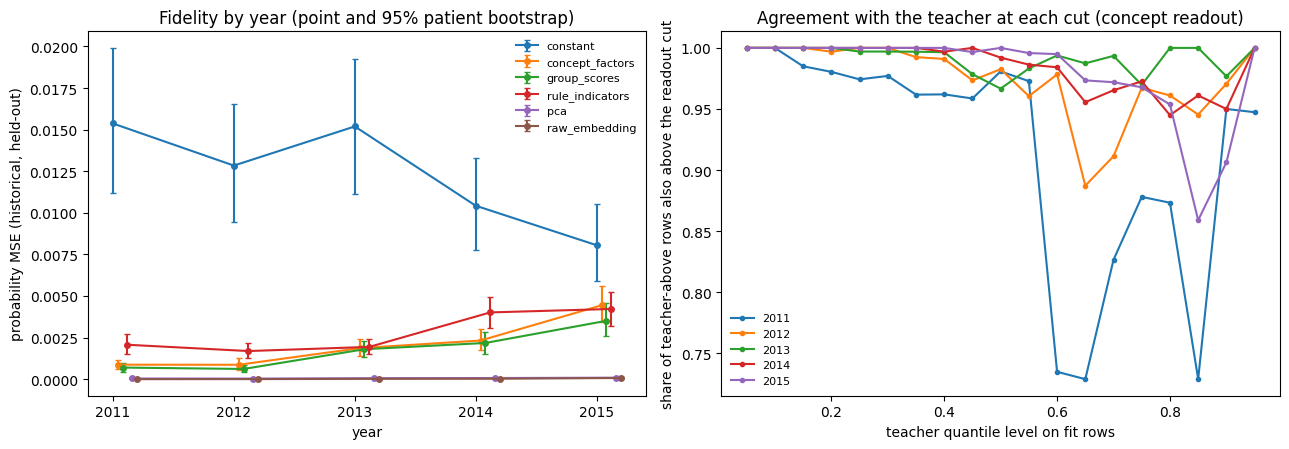

In [23]:
import matplotlib.pyplot as plt

FIGURES.mkdir(parents=True, exist_ok=True)
figure, (left, right) = plt.subplots(1, 2, figsize=(13, 4.6))
for name in ("constant", *NAMED_COMPARATORS):
    rows_for = fidelity_table[(fidelity_table["comparator"] == name) & (fidelity_table["measure"] == "probability_mse")
                              & (fidelity_table["arm"] == ARM_LABELS["historical"])]
    left.errorbar(rows_for["year"] + 0.04 * list(fidelity_table["comparator"].unique()).index(name), rows_for["estimate"],
                  yerr=[rows_for["estimate"] - rows_for["low"], rows_for["high"] - rows_for["estimate"]],
                  marker="o", ms=4, capsize=2, label=name)
left.set(xlabel="year", ylabel="probability MSE (historical, held-out)", title="Fidelity by year (point and 95% patient bootstrap)")
left.legend(frameon=False, fontsize=8)
for year in YEARS:
    curve = strata_frame[(strata_frame["comparator"] == "concept_factors") & (strata_frame["arm"] == ARM_LABELS["historical"])
                         & (strata_frame["year"] == year) & (strata_frame["cut_kind"] == "teacher quantile on fit rows")]
    right.plot(curve["level"], curve["share_of_teacher_above_also_readout_above"], marker="o", ms=3, label=str(year))
right.set(xlabel="teacher quantile level on fit rows", ylabel="share of teacher-above rows also above the readout cut",
          title="Agreement with the teacher at each cut (concept readout)")
right.legend(frameon=False, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "fidelity_and_strata.png", dpi=120)
plt.show()

## Which files does the run write, and what is recorded about the run?

The tables are written with the readouts already on disk. The run record adds the commit and the untracked files of the Fiji clone, the device, the timings and the sha256 of every output file.

In [24]:
import subprocess

import torch

fidelity_table.to_csv(OUTPUT / "fidelity.csv", index=False)
difference_table.to_csv(OUTPUT / "differences.csv", index=False)
random_table.to_csv(OUTPUT / "random_sets.csv", index=False)
random_summary.to_csv(OUTPUT / "random_sets_summary.csv", index=False)
strata_frame.to_csv(OUTPUT / "strata.csv", index=False)
mortality_table.to_csv(OUTPUT / "mortality.csv", index=False)

git_head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=paths.CODE_ROOT, capture_output=True, text=True).stdout.strip()
git_status = subprocess.run(["git", "status", "--porcelain"], cwd=paths.CODE_ROOT, capture_output=True, text=True).stdout.splitlines()
written = [OUTPUT / name for name in ("checks.csv", "readouts.npz", "fidelity.csv", "differences.csv", "random_sets.csv",
                                      "random_sets_summary.csv", "strata.csv", "mortality.csv")]
written += sorted(FIGURES.glob("*.png"))
run_record.update({
    "finished": datetime.datetime.now().isoformat(timespec="seconds"),
    "device": ("cuda" if torch.cuda.is_available() else "cpu"),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "git_head": git_head, "git_status_porcelain": git_status,
    "timings_seconds": dict(timings),
    "output_sha256": {str(path.relative_to(OUTPUT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in written},
    "random_sets_below_concept": random_summary.to_dict(orient="records"),
})
(OUTPUT / "run_record.json").write_text(json.dumps(run_record, indent=2, default=str))
print("files:", sorted(path.name for path in written))
print("timings (seconds):", {key: round(value, 1) for key, value in timings.items()})

files: ['checks.csv', 'differences.csv', 'fidelity.csv', 'fidelity_and_strata.png', 'mortality.csv', 'random_sets.csv', 'random_sets_summary.csv', 'readouts.npz', 'strata.csv']
timings (seconds): {'reference_data_seconds': 0.1, 'fit_seconds': 8.5, 'score_seconds': 22.0}
